# 02 · Exploratory analysis

Before modelling: how predictable is a Grand Prix from what we know on Sunday morning?

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from f1predict import plots
from f1predict.config import DATA_PROCESSED
from f1predict.data import load_tables
from f1predict.features import FEATURES, build_features

plots.apply_style()
t = load_tables()
df = build_features(t["races"], t["results"], t["qualifying"], t["sprints"])
df.to_parquet(DATA_PROCESSED / "features.parquet", index=False)
print(df.shape)
df[["season", "race_name", "driver_name", "constructor_name", "finish_position"] + FEATURES[:6]].head()

(5545, 51)


,season,race_name,driver_name,constructor_name,finish_position,grid,pit_lane_start,quali_position,quali_gap_pct,teammate_quali_delta,sprint_position
0,2014,Australian Grand Prix,Nico Rosberg,Mercedes,1.0,3.0,0,3.0,1.970807,0.952906,NaN
1,2014,Australian Grand Prix,Kevin Magnussen,McLaren,2.0,4.0,0,4.0,0.191683,-0.492426,NaN
2,2014,Australian Grand Prix,Jenson Button,McLaren,3.0,10.0,0,11.0,0.684109,0.492426,NaN
3,2014,Australian Grand Prix,Fernando Alonso,Ferrari,4.0,5.0,0,5.0,0.675296,-1.157808,NaN
4,2014,Australian Grand Prix,Valtteri Bottas,Williams,5.0,15.0,0,10.0,0.909942,0.410906,NaN


## 1. The grid is the single strongest signal

Pole-sitters reach the podium most of the time; from the back half of the grid a podium is rare.

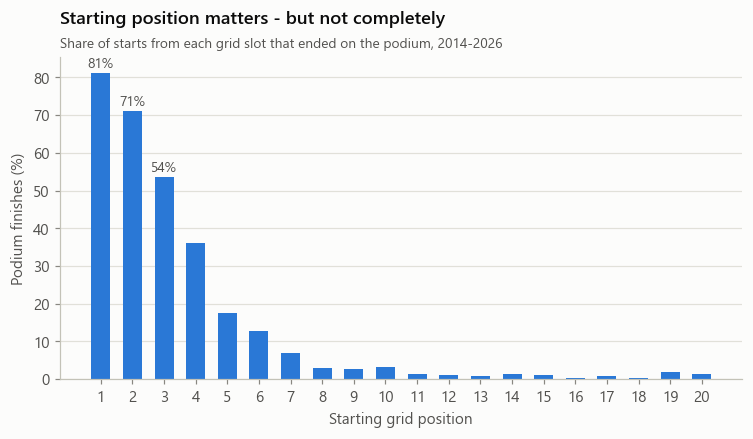

In [2]:
fig = plots.podium_rate_by_grid(df)
plots.save(fig, "podium_rate_by_grid")
plt.show()

In [3]:
pole = df[df["grid"] == 1]
print(f"Pole-sitter win rate: {pole['win'].mean():.0%} | podium rate: {pole['podium'].mean():.0%}")

Pole-sitter win rate: 55% | podium rate: 81%


## 2. ...but the era matters even more

The hybrid era has been a series of dynasties: Mercedes (2014–2020), Red Bull (2021–2023),
then McLaren. A model that knows *which car* a driver is in has a head start.

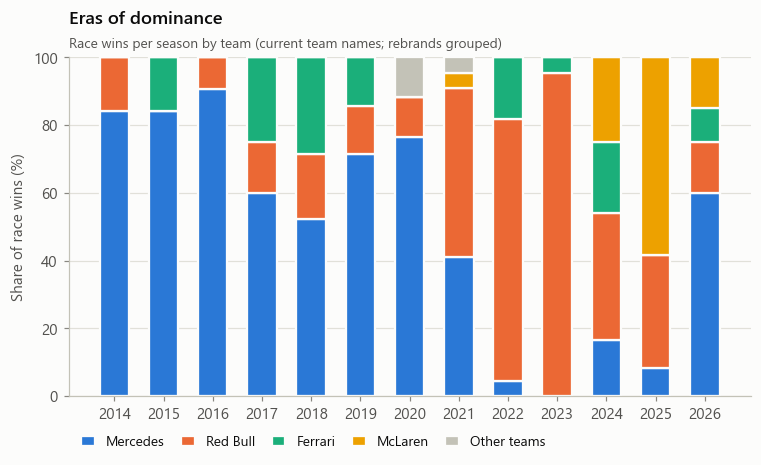

In [4]:
fig = plots.win_share_by_team(df)
plots.save(fig, "win_share_by_team")
plt.show()

## 3. Positions gained and lost

Finishing position minus grid position, for classified finishers. Most drivers finish within a
few places of where they started; the long tails are first-lap incidents, strategy and
reliability.

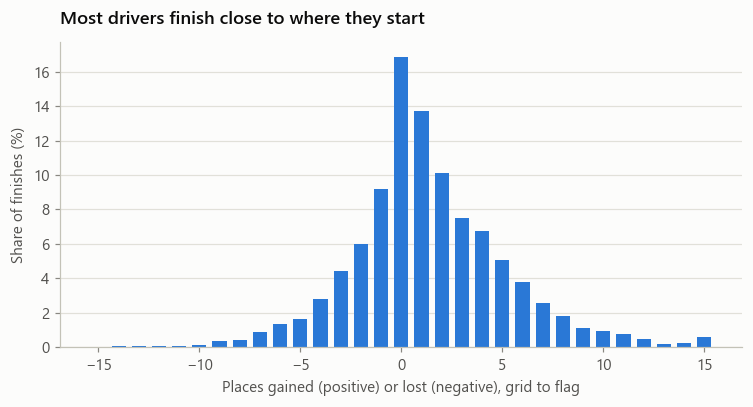

Finished within 2 places of grid: 56%


In [5]:
finishers = df[df["dnf"] == 0]
delta = (finishers["grid"] - finishers["finish_position"]).clip(-15, 15)
fig, ax = plt.subplots(figsize=(8, 3.6))
counts = delta.value_counts().sort_index()
ax.bar(counts.index, counts.values / counts.sum() * 100, width=0.7, color=plots.PALETTE[0])
ax.set_xlabel("Places gained (positive) or lost (negative), grid to flag")
ax.set_ylabel("Share of finishes (%)")
ax.grid(axis="x", visible=False)
ax.set_title("Most drivers finish close to where they start", pad=12)
plots.save(fig, "positions_gained")
plt.show()
print(f"Finished within 2 places of grid: {(delta.abs() <= 2).mean():.0%}")

## 4. Reliability over time

DNFs add irreducible noise. Retirement rates fell sharply through the hybrid era.

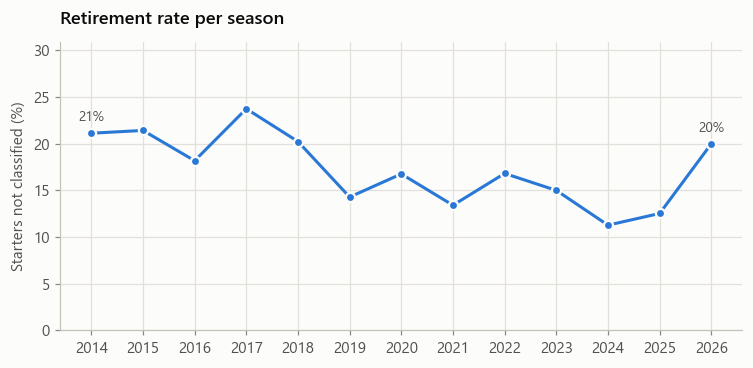

In [6]:
dnf = df.groupby("season")["dnf"].mean().mul(100)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(dnf.index, dnf.values, color=plots.PALETTE[0], marker="o", markersize=6,
        markeredgecolor=plots.SURFACE, markeredgewidth=1.5)
for s in (dnf.index.min(), dnf.index.max()):
    ax.annotate(f"{dnf[s]:.0f}%", (s, dnf[s]), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=9, color=plots.INK_2)
ax.set_xticks(dnf.index)
ax.set_ylim(0, dnf.max() * 1.3)
ax.set_ylabel("Starters not classified (%)")
ax.set_title("Retirement rate per season", pad=12)
plots.save(fig, "dnf_rate")
plt.show()

## 5. Qualifying pace vs. result

Gap to pole (in %) is a continuous measure of car + driver pace that the grid position alone
hides: P2 can be 0.01 s or 0.5 s off pole.

In [7]:
d = df[df["quali_gap_pct"].between(0, 4)]
bins = pd.cut(d["quali_gap_pct"], [0, 0.0001, 0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 2, 4],
              include_lowest=True)
summary = d.groupby(bins, observed=True).agg(podium_rate=("podium", "mean"),
                                             avg_finish=("finish_position", "mean"),
                                             n=("podium", "size"))
summary.style.format({"podium_rate": "{:.0%}", "avg_finish": "{:.1f}"})

,podium_rate,avg_finish,n
quali_gap_pct,,,
"(-0.001, 0.0001]",80%,3.3,271
"(0.0001, 0.2]",66%,4.5,191
"(0.2, 0.4]",53%,5.0,258
"(0.4, 0.6]",36%,6.2,289
"(0.6, 0.8]",22%,7.7,262
"(0.8, 1.0]",19%,8.0,292
"(1.0, 1.5]",10%,9.8,745
"(1.5, 2.0]",3%,11.3,766
"(2.0, 4.0]",0%,13.5,1836


## 6. Feature correlations with finishing position

In [8]:
corr = df[FEATURES + ["finish_position"]].corr(method="spearman")["finish_position"].drop(
    "finish_position").sort_values()
corr.to_frame("spearman_rho").style.format("{:.2f}")

,spearman_rho
drv_points_share_before,-0.61
con_points_form_5,-0.60
drv_points_form_5,-0.60
drv_podium_rate_10,-0.55
drv_starts,-0.18
drv_circuit_starts,-0.16
round,-0.01
street_circuit,0.00
pit_lane_start,0.07
teammate_quali_delta,0.15


**Takeaways for modelling**

* Grid / qualifying pace is the backbone; a "finish = grid order" baseline will be strong.
* Team strength shifts by era, so rolling team-form features should help.
* Reliability noise means we should judge models on probabilities (AUC, log loss), not only on
  picking exact positions.